# KAMARA — Baseline de classificação visual

Notebook completo para preparação, treinamento, avaliação e exportação do primeiro baseline de visão computacional do KAMARA no Google Colab.

Classes treinadas:

- `FLOOD_WATER`
- `FIRE_SMOKE`
- `OTHER`

`UNCERTAIN` não é uma classe de treinamento. Ela é uma regra de rejeição calibrada na validação a partir da confiança máxima do modelo.

O fluxo cobre aquisição, inventário, proveniência, deduplicação, agrupamento conservador de near-duplicates por pHash, split sem vazamento, MobileNetV3 com transfer learning, avaliação, calibração de rejeição e exportação ONNX.

> Antes de executar: `Runtime` → `Change runtime type` → selecione GPU.


## 0. Dependências auxiliares


In [1]:
!pip -q install "kagglehub>=1.0,<2" "ImageHash>=4.3,<5" "onnx>=1.17,<2" "onnxruntime>=1.20,<2"


## 1. Ambiente, GPU e reprodutibilidade


In [2]:
import hashlib
import json
import random
import sys
from collections import Counter
from pathlib import Path

import imagehash
import kagglehub
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    props = torch.cuda.get_device_properties(0)

    print(
        "VRAM:",
        round(props.total_memory / 1024**3, 2),
        "GB",
    )
else:
    print()
    print(
        "ATENÇÃO: GPU não detectada. "
        "Troque o runtime do Colab para GPU "
        "antes da etapa de treinamento."
    )


Python: 3.13.15
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA disponível: True
GPU: Tesla T4
VRAM: 14.56 GB


## 2. Diretórios temporários do runtime


In [3]:
WORK_DIR = Path("/content/kamara-cv")

DATA_DIR = WORK_DIR / "data"
INTERIM_DIR = WORK_DIR / "interim"
OUTPUT_DIR = WORK_DIR / "output"

DFIRE_DOWNLOAD_DIR = DATA_DIR / "dfire"
FLOOD_DOWNLOAD_DIR = DATA_DIR / "flood"

for path in [
    DATA_DIR,
    INTERIM_DIR,
    OUTPUT_DIR,
    DFIRE_DOWNLOAD_DIR,
    FLOOD_DOWNLOAD_DIR,
]:
    path.mkdir(
        parents=True,
        exist_ok=True,
    )

print("WORK_DIR:", WORK_DIR)


WORK_DIR: /content/kamara-cv


## 3. Aquisição do D-Fire

O ponto importante desta versão é que **não assumimos** que o dataset ficará em `/content/kamara-cv/data/dfire`.

O `kagglehub` pode devolver um caminho como `/kaggle/input/...`. Por isso, o restante do notebook usa sempre `DFIRE_ROOT`, criado a partir do caminho efetivamente retornado pelo download.


In [4]:
DFIRE_KAGGLE_HANDLE = (
    "sayedgamal99/smoke-fire-detection-yolo"
)

print("Obtendo D-Fire...")

dfire_download_path = kagglehub.dataset_download(
    DFIRE_KAGGLE_HANDLE,
    output_dir=str(DFIRE_DOWNLOAD_DIR),
)

DFIRE_ROOT = Path(
    dfire_download_path
).resolve()

if not DFIRE_ROOT.exists():
    raise FileNotFoundError(
        f"D-Fire não encontrado em {DFIRE_ROOT}"
    )

print()
print("D-Fire root:", DFIRE_ROOT)
print("Existe:", DFIRE_ROOT.exists())


Obtendo D-Fire...
Using Colab cache for faster access to the 'smoke-fire-detection-yolo' dataset.

D-Fire root: /kaggle/input/smoke-fire-detection-yolo
Existe: True


## 4. Aquisição do dataset de inundação



In [5]:
FLOOD_KAGGLE_HANDLE = (
    "dhawalsrivastava2583/"
    "flood-classification-dataset"
)

print("Obtendo dataset de inundação...")

flood_download_path = kagglehub.dataset_download(
    FLOOD_KAGGLE_HANDLE,
    output_dir=str(FLOOD_DOWNLOAD_DIR),
)

FLOOD_ROOT = Path(
    flood_download_path
).resolve()

if not FLOOD_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset de inundação não encontrado em {FLOOD_ROOT}"
    )

FLOOD_SOURCE_DATASET = "flood-kaggle-fallback"

print()
print("Flood root:", FLOOD_ROOT)
print("Existe:", FLOOD_ROOT.exists())
print("Identificador:", FLOOD_SOURCE_DATASET)


Obtendo dataset de inundação...
Using Colab cache for faster access to the 'flood-classification-dataset' dataset.

Flood root: /kaggle/input/flood-classification-dataset
Existe: True
Identificador: flood-kaggle-fallback


## 5. Funções de inspeção e estrutura real dos datasets


In [6]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp",
    ".tif",
    ".tiff",
}


def discover_images(
    root: Path,
) -> list[Path]:
    return sorted(
        path
        for path in Path(root).rglob("*")
        if (
            path.is_file()
            and path.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    )


def count_images(
    root: Path,
) -> int:
    return len(
        discover_images(root)
    )


def print_tree(
    root: Path,
    max_depth: int = 3,
    max_entries: int = 120,
) -> None:
    root = Path(root)

    print()
    print(root)

    count = 0

    for path in sorted(
        root.rglob("*")
    ):
        relative = path.relative_to(
            root
        )

        depth = len(
            relative.parts
        )

        if depth > max_depth:
            continue

        indent = "  " * (
            depth - 1
        )

        marker = (
            "/"
            if path.is_dir()
            else ""
        )

        print(
            f"{indent}- "
            f"{relative}{marker}"
        )

        count += 1

        if count >= max_entries:
            print(
                "... saída truncada ..."
            )
            break


print("=" * 80)
print("D-FIRE")
print("=" * 80)

print_tree(
    DFIRE_ROOT,
    max_depth=4,
    max_entries=80,
)

print()
print(
    "Imagens D-Fire:",
    count_images(DFIRE_ROOT),
)


print()
print("=" * 80)
print("FLOOD")
print("=" * 80)

print_tree(
    FLOOD_ROOT,
    max_depth=3,
    max_entries=80,
)

print()
print(
    "Imagens flood:",
    count_images(FLOOD_ROOT),
)


D-FIRE

/kaggle/input/smoke-fire-detection-yolo
- data/
  - data/test/
    - data/test/images/
      - data/test/images/AoF06723.jpg
      - data/test/images/AoF06724.jpg
      - data/test/images/AoF06725.jpg
      - data/test/images/AoF06726.jpg
      - data/test/images/AoF06727.jpg
      - data/test/images/AoF06728.jpg
      - data/test/images/AoF06729.jpg
      - data/test/images/AoF06730.jpg
      - data/test/images/AoF06731.jpg
      - data/test/images/AoF06732.jpg
      - data/test/images/AoF06733.jpg
      - data/test/images/AoF06734.jpg
      - data/test/images/AoF06735.jpg
      - data/test/images/AoF06736.jpg
      - data/test/images/AoF06737.jpg
      - data/test/images/AoF06738.jpg
      - data/test/images/AoF06739.jpg
      - data/test/images/AoF06740.jpg
      - data/test/images/AoF06741.jpg
      - data/test/images/AoF06742.jpg
      - data/test/images/AoF06743.jpg
      - data/test/images/AoF06744.jpg
      - data/test/images/AoF06745.jpg
      - data/test/images/AoF067

## 6. Inventário neutro

O inventário ainda não usa as classes finais do KAMARA.

Para cada imagem registramos:

- dataset de origem;
- caminho relativo;
- tamanho do arquivo;
- SHA-256;
- perceptual hash (`pHash`);
- dimensões;
- formato;
- validade.

O SHA-256 encontra duplicatas exatas. O pHash será útil na próxima fase para detectar imagens visualmente muito parecidas.


In [7]:
def sha256_file(
    path: Path,
    chunk_size: int = 1024 * 1024,
) -> str:
    digest = hashlib.sha256()

    with path.open("rb") as file:
        while True:
            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


def inventory_dataset(
    root: Path,
    source_dataset: str,
) -> list[dict]:
    root = Path(root)

    image_paths = discover_images(
        root
    )

    print(
        f"{source_dataset}: "
        f"{len(image_paths)} imagem(ns)"
    )

    rows = []

    for path in tqdm(
        image_paths,
        desc=source_dataset,
    ):
        relative_path = (
            path
            .relative_to(root)
            .as_posix()
        )

        sha256 = sha256_file(
            path
        )

        try:
            with Image.open(
                path
            ) as image:
                image.load()

                width, height = (
                    image.size
                )

                image_format = (
                    image.format
                )

                image_mode = (
                    image.mode
                )

                phash = str(
                    imagehash.phash(
                        image.convert(
                            "RGB"
                        )
                    )
                )

            valid_image = True
            error = None

        except (
            UnidentifiedImageError,
            OSError,
            ValueError,
        ) as exc:
            width = None
            height = None
            image_format = None
            image_mode = None
            phash = None
            valid_image = False
            error = str(exc)

        rows.append(
            {
                "source_dataset": (
                    source_dataset
                ),
                "relative_path": (
                    relative_path
                ),
                "filename": path.name,
                "extension": (
                    path.suffix.lower()
                ),
                "file_size_bytes": (
                    path.stat().st_size
                ),
                "sha256": sha256,
                "phash": phash,
                "width": width,
                "height": height,
                "image_format": (
                    image_format
                ),
                "image_mode": (
                    image_mode
                ),
                "valid_image": (
                    valid_image
                ),
                "error": error,
            }
        )

    return rows


rows = []

rows.extend(
    inventory_dataset(
        DFIRE_ROOT,
        "dfire",
    )
)

rows.extend(
    inventory_dataset(
        FLOOD_ROOT,
        FLOOD_SOURCE_DATASET,
    )
)

inventory = pd.DataFrame(
    rows
)

if inventory.empty:
    raise RuntimeError(
        "Nenhuma imagem encontrada."
    )

inventory[
    "duplicate_exact"
] = inventory.duplicated(
    subset=[
        "sha256",
    ],
    keep=False,
)

inventory[
    "exact_duplicate_count"
] = (
    inventory
    .groupby(
        "sha256"
    )[
        "sha256"
    ]
    .transform(
        "size"
    )
)

inventory_path = (
    INTERIM_DIR
    / "raw_inventory.csv"
)

inventory.to_csv(
    inventory_path,
    index=False,
)

print()
print(
    "Inventário salvo em:",
    inventory_path,
)

display(
    inventory.head()
)


dfire: 21527 imagem(ns)


dfire:   0%|          | 0/21527 [00:00<?, ?it/s]

flood-kaggle-fallback: 13044 imagem(ns)


flood-kaggle-fallback:   0%|          | 0/13044 [00:00<?, ?it/s]


Inventário salvo em: /content/kamara-cv/interim/raw_inventory.csv


,source_dataset,relative_path,filename,extension,file_size_bytes,sha256,phash,width,height,image_format,image_mode,valid_image,error,duplicate_exact,exact_duplicate_count
0,dfire,data/test/images/AoF06723.jpg,AoF06723.jpg,.jpg,227556,3eb16b635a007bdd6353e7219cae149a7da2f05153b2bb...,e5dd83928a2c3575,1280,720,JPEG,RGB,True,None,False,1
1,dfire,data/test/images/AoF06724.jpg,AoF06724.jpg,.jpg,214654,3d575c00fa660b59febf3f7c748b6583ac338171b0b5db...,c7f8831313a6fc31,1270,685,JPEG,RGB,True,None,False,1
2,dfire,data/test/images/AoF06725.jpg,AoF06725.jpg,.jpg,182043,6143934eb0bfb7b66f6f171d3087d57615d78135c0b483...,cfac810362a6fc3d,1267,702,JPEG,RGB,True,None,False,1
3,dfire,data/test/images/AoF06726.jpg,AoF06726.jpg,.jpg,202054,abc09c6dd90c7bd244e5f8bffd9980088a269e365b581d...,dfa983833135784d,1278,712,JPEG,RGB,True,None,False,1
4,dfire,data/test/images/AoF06727.jpg,AoF06727.jpg,.jpg,190405,329dcbc630fe1718c567a7e01bbfea9a8faadf7bbe6f72...,8b9d95c2c4276c79,1276,717,JPEG,RGB,True,None,False,1


## 7. Resumo do inventário


In [8]:
summary = (
    inventory
    .groupby(
        "source_dataset"
    )
    .agg(
        files=(
            "relative_path",
            "size",
        ),
        valid_images=(
            "valid_image",
            "sum",
        ),
        unique_sha256=(
            "sha256",
            "nunique",
        ),
        exact_duplicate_files=(
            "duplicate_exact",
            "sum",
        ),
        min_width=(
            "width",
            "min",
        ),
        max_width=(
            "width",
            "max",
        ),
        min_height=(
            "height",
            "min",
        ),
        max_height=(
            "height",
            "max",
        ),
    )
    .reset_index()
)

display(
    summary
)


cross_dataset = (
    inventory[
        inventory[
            "duplicate_exact"
        ]
    ]
    .groupby(
        "sha256"
    )[
        "source_dataset"
    ]
    .nunique()
)

cross_dataset = (
    cross_dataset[
        cross_dataset > 1
    ]
)

print()
print(
    "Duplicatas exatas entre datasets:",
    int(
        cross_dataset.shape[0]
    ),
)


,source_dataset,files,valid_images,unique_sha256,exact_duplicate_files,min_width,max_width,min_height,max_height
0,dfire,21527,21527,21527,0,162,4288,142,2848
1,flood-kaggle-fallback,13044,13044,10757,3845,194,6999,113,5020



Duplicatas exatas entre datasets: 0


## 8. Diagnóstico da organização dos datasets


In [9]:
def image_counts_by_parent(
    root: Path,
    max_levels: int = 4,
) -> Counter:
    root = Path(root)

    counter = Counter()

    for path in discover_images(
        root
    ):
        relative = path.relative_to(
            root
        )

        parent_parts = (
            relative.parts[:-1]
        )

        parent_key = "/".join(
            parent_parts[
                :max_levels
            ]
        )

        counter[
            parent_key
        ] += 1

    return counter


print("=" * 80)
print("D-FIRE")
print("=" * 80)

for folder, count in (
    image_counts_by_parent(
        DFIRE_ROOT
    )
    .most_common(30)
):
    print(
        f"{count:6d}  {folder}"
    )


print()
print("=" * 80)
print("FLOOD")
print("=" * 80)

for folder, count in (
    image_counts_by_parent(
        FLOOD_ROOT
    )
    .most_common(30)
):
    print(
        f"{count:6d}  {folder}"
    )


print()
print("=" * 80)
print("EXEMPLOS DE CAMINHOS")
print("=" * 80)

for source_dataset in (
    inventory[
        "source_dataset"
    ].unique()
):
    print()
    print(source_dataset)

    sample = (
        inventory[
            inventory[
                "source_dataset"
            ]
            == source_dataset
        ][
            "relative_path"
        ]
        .head(15)
        .tolist()
    )

    for relative_path in sample:
        print(
            relative_path
        )


D-FIRE
 14122  data/train/images
  4306  data/test/images
  3099  data/val/images

FLOOD
  9296  Dataset/Flood Images
  3748  Dataset/Non Flood Images

EXEMPLOS DE CAMINHOS

dfire
data/test/images/AoF06723.jpg
data/test/images/AoF06724.jpg
data/test/images/AoF06725.jpg
data/test/images/AoF06726.jpg
data/test/images/AoF06727.jpg
data/test/images/AoF06728.jpg
data/test/images/AoF06729.jpg
data/test/images/AoF06730.jpg
data/test/images/AoF06731.jpg
data/test/images/AoF06732.jpg
data/test/images/AoF06733.jpg
data/test/images/AoF06734.jpg
data/test/images/AoF06735.jpg
data/test/images/AoF06736.jpg
data/test/images/AoF06737.jpg

flood-kaggle-fallback
Dataset/Flood Images/Flood_1000.jpg
Dataset/Flood Images/Flood_1002.jpg
Dataset/Flood Images/Flood_1011.jpg
Dataset/Flood Images/Flood_1012.jpg
Dataset/Flood Images/Flood_1021.jpg
Dataset/Flood Images/Flood_1023.jpg
Dataset/Flood Images/Flood_1025.jpg
Dataset/Flood Images/Flood_1027.jpg
Dataset/Flood Images/Flood_1028.jpg
Dataset/Flood Images/Fl

## 9. Validação dos rótulos do D-Fire

O D-Fire usa arquivos de anotação associados às imagens.

Para o classificador do KAMARA, não precisamos separar fogo de fumaça nesta primeira versão:

- arquivo de rótulo com pelo menos uma anotação → `FIRE_SMOKE`;
- arquivo de rótulo vazio → `OTHER`.

Antes de aplicar essa regra, validamos se cada imagem possui o arquivo de rótulo correspondente.


In [10]:
LABEL_EXTENSIONS = {
    ".txt",
    ".json",
    ".csv",
    ".xml",
    ".yaml",
    ".yml",
}


label_files = sorted(
    path
    for path in DFIRE_ROOT.rglob("*")
    if (
        path.is_file()
        and path.suffix.lower()
        in LABEL_EXTENSIONS
    )
)


label_extension_counts = Counter(
    path.suffix.lower()
    for path in label_files
)


print(
    "Arquivos potenciais "
    "de rótulo:",
    len(label_files),
)

print()
print(
    "Arquivos por extensão:"
)

for extension, count in sorted(
    label_extension_counts.items()
):
    print(
        f"{extension}: {count}"
    )


yaml_files = sorted(
    path
    for path in DFIRE_ROOT.rglob("*")
    if (
        path.is_file()
        and path.suffix.lower()
        in {
            ".yaml",
            ".yml",
        }
    )
)

print()
print(
    "Arquivos YAML:",
    len(yaml_files),
)

for path in yaml_files:
    print()
    print("=" * 80)

    print(
        path.relative_to(
            DFIRE_ROOT
        )
    )

    print("=" * 80)

    print(
        path.read_text(
            encoding="utf-8",
            errors="replace",
        )[:3000]
    )


Arquivos potenciais de rótulo: 21528

Arquivos por extensão:
.txt: 21527
.yaml: 1

Arquivos YAML: 1

data.yaml
path: /kaggle/working/D Fire Dataset  # dataset root dir
train: data/train/images  # train images (relative to 'path')
val: data/val/images  # val images (relative to 'path')
test: data/test/images  # test images (relative to 'path')

# Classes
names: ['smoke', 'fire']  # Replace with your actual class names

# Counts
nc: 2  # number of classes
train_count: 14122
val_count: 3099
test_count: 4306



In [11]:
def dfire_label_path(
    image_path: Path,
) -> Path:
    relative = image_path.relative_to(
        DFIRE_ROOT
    )

    parts = list(
        relative.parts
    )

    try:
        images_index = parts.index(
            "images"
        )

    except ValueError as error:
        raise ValueError(
            "Caminho de imagem D-Fire "
            f"inesperado: {relative}"
        ) from error

    parts[
        images_index
    ] = "labels"

    relative_label = (
        Path(
            *parts
        )
        .with_suffix(
            ".txt"
        )
    )

    return (
        DFIRE_ROOT
        / relative_label
    )


dfire_images = discover_images(
    DFIRE_ROOT
)

missing_labels = []
empty_labels = []
non_empty_labels = []


for image_path in tqdm(
    dfire_images,
    desc="Validando rótulos D-Fire",
):
    label_path = dfire_label_path(
        image_path
    )

    if not label_path.exists():
        missing_labels.append(
            image_path
        )

        continue

    content = (
        label_path
        .read_text(
            encoding="utf-8",
            errors="replace",
        )
        .strip()
    )

    if content:
        non_empty_labels.append(
            image_path
        )
    else:
        empty_labels.append(
            image_path
        )


print()
print(
    "Imagens:",
    len(dfire_images),
)

print(
    "Labels ausentes:",
    len(missing_labels),
)

print(
    "Labels vazios:",
    len(empty_labels),
)

print(
    "Labels com fire/smoke:",
    len(non_empty_labels),
)


if missing_labels:
    print()
    print(
        "ATENÇÃO: existem imagens "
        "sem arquivo de rótulo."
    )


Validando rótulos D-Fire:   0%|          | 0/21527 [00:00<?, ?it/s]


Imagens: 21527
Labels ausentes: 0
Labels vazios: 9838
Labels com fire/smoke: 11689


## 10. Construção do manifesto rotulado


In [12]:
def build_dfire_labels(
    root: Path,
) -> pd.DataFrame:
    rows = []

    for image_path in discover_images(
        root
    ):
        label_path = dfire_label_path(
            image_path
        )

        if not label_path.exists():
            continue

        content = (
            label_path
            .read_text(
                encoding="utf-8",
                errors="replace",
            )
            .strip()
        )

        relative = (
            image_path
            .relative_to(root)
        )

        source_split = None

        for candidate in (
            "train",
            "val",
            "test",
        ):
            if candidate in (
                relative.parts
            ):
                source_split = (
                    candidate
                )

                break

        rows.append(
            {
                "relative_path": (
                    relative.as_posix()
                ),
                "label": (
                    "FIRE_SMOKE"
                    if content
                    else "OTHER"
                ),
                "source_original_label": (
                    "fire_or_smoke"
                    if content
                    else "none"
                ),
                "source_split": (
                    source_split
                ),
            }
        )

    return pd.DataFrame(
        rows
    )


def build_flood_labels(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    result = dataframe.copy()

    def classify_path(
        relative_path: str,
    ) -> str:
        normalized = (
            relative_path
            .replace(
                "\\",
                "/",
            )
        )

        wrapped = (
            f"/{normalized}/"
        )

        if (
            "/Flood Images/"
            in wrapped
        ):
            return (
                "FLOOD_WATER"
            )

        if (
            "/Non Flood Images/"
            in wrapped
        ):
            return "OTHER"

        raise ValueError(
            "Não foi possível determinar "
            "o rótulo do dataset flood: "
            f"{relative_path}"
        )

    result[
        "label"
    ] = result[
        "relative_path"
    ].map(
        classify_path
    )

    result[
        "source_original_label"
    ] = result[
        "label"
    ].map(
        {
            "FLOOD_WATER": (
                "flood"
            ),
            "OTHER": (
                "non_flood"
            ),
        }
    )

    result[
        "source_split"
    ] = None

    return result


dfire_inventory = (
    inventory[
        inventory[
            "source_dataset"
        ]
        == "dfire"
    ]
    .copy()
)


flood_inventory = (
    inventory[
        inventory[
            "source_dataset"
        ]
        == FLOOD_SOURCE_DATASET
    ]
    .copy()
)


dfire_labels = build_dfire_labels(
    DFIRE_ROOT
)


dfire_manifest = (
    dfire_inventory
    .merge(
        dfire_labels,
        on="relative_path",
        how="inner",
        validate="one_to_one",
    )
)


flood_manifest = build_flood_labels(
    flood_inventory
)


manifest = pd.concat(
    [
        dfire_manifest,
        flood_manifest,
    ],
    ignore_index=True,
)


print(
    "Total rotulado:",
    len(manifest),
)

print()
print(
    "Distribuição por classe:"
)

display(
    manifest[
        "label"
    ]
    .value_counts()
    .rename_axis(
        "label"
    )
    .reset_index(
        name="files"
    )
)


print()
print(
    "Dataset x classe:"
)

display(
    pd.crosstab(
        manifest[
            "source_dataset"
        ],
        manifest[
            "label"
        ],
    )
)


Total rotulado: 34571

Distribuição por classe:


,label,files
0,OTHER,13586
1,FIRE_SMOKE,11689
2,FLOOD_WATER,9296



Dataset x classe:


label,FIRE_SMOKE,FLOOD_WATER,OTHER
source_dataset,,,
dfire,11689,0,9838
flood-kaggle-fallback,0,9296,3748


## 11. Duplicatas exatas e conflitos de rótulo


In [13]:
hash_label_count = (
    manifest
    .groupby(
        "sha256"
    )[
        "label"
    ]
    .nunique()
)


conflicting_hashes = set(
    hash_label_count[
        hash_label_count > 1
    ].index
)


manifest[
    "label_conflict"
] = manifest[
    "sha256"
].isin(
    conflicting_hashes
)


manifest[
    "duplicate_exact"
] = manifest.duplicated(
    subset=[
        "sha256",
    ],
    keep=False,
)


manifest[
    "exact_duplicate_count"
] = (
    manifest
    .groupby(
        "sha256"
    )[
        "sha256"
    ]
    .transform(
        "size"
    )
)


print(
    "Hashes com rótulos conflitantes:",
    len(
        conflicting_hashes
    ),
)

print(
    "Arquivos em grupos duplicados:",
    int(
        manifest[
            "duplicate_exact"
        ].sum()
    ),
)

print(
    "Arquivos envolvidos "
    "em conflito de classe:",
    int(
        manifest[
            "label_conflict"
        ].sum()
    ),
)


if conflicting_hashes:
    print()
    print(
        "Exemplos de conflitos:"
    )

    display(
        manifest[
            manifest[
                "label_conflict"
            ]
        ][
            [
                "source_dataset",
                "relative_path",
                "label",
                "sha256",
            ]
        ]
        .sort_values(
            [
                "sha256",
                "label",
            ]
        )
        .head(30)
    )


Hashes com rótulos conflitantes: 0
Arquivos em grupos duplicados: 3845
Arquivos envolvidos em conflito de classe: 0


## 12. Persistência dos artefatos de preparação


In [14]:
manifest_path = (
    INTERIM_DIR
    / "labeled_manifest.csv"
)

manifest.to_csv(
    manifest_path,
    index=False,
)


diagnostics = {
    "seed": SEED,
    "dfire_root": str(
        DFIRE_ROOT
    ),
    "flood_root": str(
        FLOOD_ROOT
    ),
    "flood_source_dataset": (
        FLOOD_SOURCE_DATASET
    ),
    "total_images_inventory": int(
        len(inventory)
    ),
    "total_images_labeled": int(
        len(manifest)
    ),
    "class_counts": {
        str(label): int(count)
        for label, count in (
            manifest[
                "label"
            ]
            .value_counts()
            .items()
        )
    },
    "hashes_with_label_conflict": int(
        len(
            conflicting_hashes
        )
    ),
    "files_in_exact_duplicate_groups": int(
        manifest[
            "duplicate_exact"
        ].sum()
    ),
    "files_in_label_conflicts": int(
        manifest[
            "label_conflict"
        ].sum()
    ),
    "dfire_missing_labels": int(
        len(
            missing_labels
        )
    ),
    "dfire_empty_labels": int(
        len(
            empty_labels
        )
    ),
    "dfire_non_empty_labels": int(
        len(
            non_empty_labels
        )
    ),
}


diagnostics_path = (
    OUTPUT_DIR
    / "data_preparation_diagnostics.json"
)


diagnostics_path.write_text(
    json.dumps(
        diagnostics,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


print(
    "Inventário:",
    inventory_path,
)

print(
    "Manifesto:",
    manifest_path,
)

print(
    "Diagnóstico:",
    diagnostics_path,
)

print()

print(
    json.dumps(
        diagnostics,
        ensure_ascii=False,
        indent=2,
    )
)


Inventário: /content/kamara-cv/interim/raw_inventory.csv
Manifesto: /content/kamara-cv/interim/labeled_manifest.csv
Diagnóstico: /content/kamara-cv/output/data_preparation_diagnostics.json

{
  "seed": 42,
  "dfire_root": "/kaggle/input/smoke-fire-detection-yolo",
  "flood_root": "/kaggle/input/flood-classification-dataset",
  "flood_source_dataset": "flood-kaggle-fallback",
  "total_images_inventory": 34571,
  "total_images_labeled": 34571,
  "class_counts": {
    "OTHER": 13586,
    "FIRE_SMOKE": 11689,
    "FLOOD_WATER": 9296
  },
  "hashes_with_label_conflict": 0,
  "files_in_exact_duplicate_groups": 3845,
  "files_in_label_conflicts": 0,
  "dfire_missing_labels": 0,
  "dfire_empty_labels": 9838,
  "dfire_non_empty_labels": 11689
}


## 14. Deduplicação exata

Primeiro removemos:

1. imagens inválidas;
2. hashes que possuem conflito de rótulo;
3. cópias byte-a-byte identificadas pelo mesmo SHA-256.

Para cada SHA-256 sem conflito mantemos uma única imagem representante. Nenhum split é criado nesta etapa.


In [15]:
model_manifest = (
    manifest[
        manifest["valid_image"]
    ]
    .copy()
)

if conflicting_hashes:
    model_manifest = model_manifest[
        ~model_manifest[
            "sha256"
        ].isin(
            conflicting_hashes
        )
    ].copy()

before_exact_dedup = len(
    model_manifest
)

model_manifest = (
    model_manifest
    .sort_values(
        [
            "source_dataset",
            "label",
            "relative_path",
        ]
    )
    .drop_duplicates(
        subset=["sha256"],
        keep="first",
    )
    .reset_index(drop=True)
)

exact_duplicates_removed = (
    before_exact_dedup
    - len(model_manifest)
)

print(
    "Antes da deduplicação exata:",
    before_exact_dedup,
)

print(
    "Depois da deduplicação exata:",
    len(model_manifest),
)

print(
    "Cópias exatas removidas:",
    exact_duplicates_removed,
)

print()
print("Distribuição após deduplicação:")

display(
    model_manifest[
        "label"
    ]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="files")
)

exact_dedup_path = (
    INTERIM_DIR
    / "exact_dedup_manifest.csv"
)

model_manifest.to_csv(
    exact_dedup_path,
    index=False,
)

print()
print(
    "Manifesto deduplicado:",
    exact_dedup_path,
)


Antes da deduplicação exata: 34571
Depois da deduplicação exata: 32284
Cópias exatas removidas: 2287

Distribuição após deduplicação:


,label,files
0,OTHER,13585
1,FIRE_SMOKE,11689
2,FLOOD_WATER,7010



Manifesto deduplicado: /content/kamara-cv/interim/exact_dedup_manifest.csv


## 15. Near-duplicates com pHash e grupos de vazamento

SHA-256 só encontra arquivos idênticos. Para reduzir vazamento por imagens redimensionadas, recomprimidas ou muito parecidas, usamos o pHash já calculado.

O pHash usado aqui possui 64 bits. Consideramos **candidatos a near-duplicate** imagens com distância de Hamming `<= 4`. Esta é uma regra conservadora para agrupamento de split, não uma afirmação de que as imagens são semanticamente idênticas.

Para evitar comparação O(N²), usamos uma BK-tree e Union-Find.


In [16]:
PHASH_MAX_DISTANCE = 4


def hamming_distance(
    left: int,
    right: int,
) -> int:
    return (
        left ^ right
    ).bit_count()


class UnionFind:
    def __init__(
        self,
        size: int,
    ) -> None:
        self.parent = list(
            range(size)
        )

        self.rank = [
            0
        ] * size

    def find(
        self,
        item: int,
    ) -> int:
        while (
            self.parent[item]
            != item
        ):
            self.parent[item] = (
                self.parent[
                    self.parent[item]
                ]
            )

            item = self.parent[
                item
            ]

        return item

    def union(
        self,
        left: int,
        right: int,
    ) -> None:
        left_root = self.find(
            left
        )

        right_root = self.find(
            right
        )

        if (
            left_root
            == right_root
        ):
            return

        if (
            self.rank[left_root]
            < self.rank[right_root]
        ):
            left_root, right_root = (
                right_root,
                left_root,
            )

        self.parent[
            right_root
        ] = left_root

        if (
            self.rank[left_root]
            == self.rank[right_root]
        ):
            self.rank[
                left_root
            ] += 1


class BKNode:
    def __init__(
        self,
        value: int,
        index: int,
    ) -> None:
        self.value = value
        self.index = index
        self.children = {}


class BKTree:
    def __init__(self) -> None:
        self.root = None

    def add(
        self,
        value: int,
        index: int,
    ) -> None:
        if self.root is None:
            self.root = BKNode(
                value,
                index,
            )

            return

        node = self.root

        while True:
            distance = hamming_distance(
                value,
                node.value,
            )

            if distance == 0:
                # Um representante deste pHash já está na árvore.
                return

            child = node.children.get(
                distance
            )

            if child is None:
                node.children[
                    distance
                ] = BKNode(
                    value,
                    index,
                )

                return

            node = child

    def search(
        self,
        value: int,
        max_distance: int,
    ) -> list[int]:
        if self.root is None:
            return []

        result = []
        stack = [
            self.root
        ]

        while stack:
            node = stack.pop()

            distance = hamming_distance(
                value,
                node.value,
            )

            if (
                distance
                <= max_distance
            ):
                result.append(
                    node.index
                )

            lower = (
                distance
                - max_distance
            )

            upper = (
                distance
                + max_distance
            )

            for edge_distance, child in (
                node.children.items()
            ):
                if (
                    lower
                    <= edge_distance
                    <= upper
                ):
                    stack.append(
                        child
                    )

        return result


def parse_phash(
    value,
) -> int | None:
    if pd.isna(value):
        return None

    text = str(
        value
    ).strip()

    if not text:
        return None

    return int(
        text,
        16,
    )


union_find = UnionFind(
    len(model_manifest)
)

tree = BKTree()

phash_values = (
    model_manifest[
        "phash"
    ].tolist()
)

for index, raw_value in enumerate(
    tqdm(
        phash_values,
        desc="Agrupando pHash",
    )
):
    value = parse_phash(
        raw_value
    )

    if value is None:
        continue

    matches = tree.search(
        value,
        PHASH_MAX_DISTANCE,
    )

    for other_index in matches:
        union_find.union(
            index,
            other_index,
        )

    tree.add(
        value,
        index,
    )


roots = [
    union_find.find(index)
    for index in range(
        len(model_manifest)
    )
]

root_to_group = {
    root: (
        f"phash-group-"
        f"{position:06d}"
    )
    for position, root in enumerate(
        sorted(
            set(roots)
        )
    )
}

model_manifest[
    "group_id"
] = [
    root_to_group[
        root
    ]
    for root in roots
]


group_summary = (
    model_manifest
    .groupby(
        "group_id"
    )
    .agg(
        files=(
            "relative_path",
            "size",
        ),
        label_count=(
            "label",
            "nunique",
        ),
        dataset_count=(
            "source_dataset",
            "nunique",
        ),
    )
    .reset_index()
)


near_duplicate_groups = (
    group_summary[
        group_summary[
            "files"
        ]
        > 1
    ]
)


near_duplicate_conflict_groups = set(
    group_summary[
        group_summary[
            "label_count"
        ]
        > 1
    ][
        "group_id"
    ]
)


model_manifest[
    "near_duplicate_candidate"
] = model_manifest[
    "group_id"
].isin(
    set(
        near_duplicate_groups[
            "group_id"
        ]
    )
)


model_manifest[
    "near_duplicate_label_conflict"
] = model_manifest[
    "group_id"
].isin(
    near_duplicate_conflict_groups
)


dfire_original_split_groups = (
    model_manifest[
        (
            model_manifest[
                "source_dataset"
            ]
            == "dfire"
        )
        & model_manifest[
            "source_split"
        ].notna()
    ]
    .groupby(
        "group_id"
    )[
        "source_split"
    ]
    .nunique()
)


dfire_cross_original_split_groups = (
    dfire_original_split_groups[
        dfire_original_split_groups
        > 1
    ]
)


print(
    "Grupos totais:",
    group_summary.shape[0],
)

print(
    "Grupos com 2+ imagens:",
    near_duplicate_groups.shape[0],
)

print(
    "Arquivos em grupos candidatos a near-duplicate:",
    int(
        model_manifest[
            "near_duplicate_candidate"
        ].sum()
    ),
)

print(
    "Grupos pHash com conflito de classe:",
    len(
        near_duplicate_conflict_groups
    ),
)

print(
    "Grupos D-Fire que atravessam "
    "o split original:",
    int(
        dfire_cross_original_split_groups.shape[0]
    ),
)

print()
print(
    "Maiores grupos:"
)

display(
    group_summary
    .sort_values(
        "files",
        ascending=False,
    )
    .head(20)
)


Agrupando pHash:   0%|          | 0/32284 [00:00<?, ?it/s]

Grupos totais: 20825
Grupos com 2+ imagens: 1221
Arquivos em grupos candidatos a near-duplicate: 12680
Grupos pHash com conflito de classe: 43
Grupos D-Fire que atravessam o split original: 629

Maiores grupos:


,group_id,files,label_count,dataset_count
59,phash-group-000059,1206,2,1
41,phash-group-000041,1055,2,1
7723,phash-group-007723,653,1,1
91,phash-group-000091,623,2,1
8,phash-group-000008,354,1,1
16854,phash-group-016854,267,1,1
16848,phash-group-016848,248,1,1
37,phash-group-000037,245,2,1
16856,phash-group-016856,214,1,1
16646,phash-group-016646,168,1,1


## 16. Construção do split por grupos

Grupos pHash com mais de uma classe são retirados do baseline, pois podem representar ambiguidade ou falsos positivos da heurística de near-duplicate.

O split é construído **por `group_id`**, nunca por imagem isolada. Assim, um mesmo grupo não pode aparecer em treino e teste.

A divisão alvo é:

- treino: 70%
- validação: 15%
- teste: 15%

O balanceamento é feito separadamente por `source_dataset + label`, preservando aproximadamente a composição de origem e classe em cada split.


In [17]:
SPLIT_RATIOS = {
    "train": 0.70,
    "val": 0.15,
    "test": 0.15,
}


split_manifest = (
    model_manifest[
        ~model_manifest[
            "near_duplicate_label_conflict"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)


group_table = (
    split_manifest
    .groupby(
        "group_id"
    )
    .agg(
        label=(
            "label",
            "first",
        ),
        source_dataset=(
            "source_dataset",
            lambda values: "|".join(
                sorted(
                    set(values)
                )
            ),
        ),
        files=(
            "relative_path",
            "size",
        ),
    )
    .reset_index()
)


group_table[
    "stratum"
] = (
    group_table[
        "source_dataset"
    ]
    + "|"
    + group_table[
        "label"
    ]
)


rng = np.random.default_rng(
    SEED
)

group_to_split = {}


for stratum, frame in (
    group_table
    .groupby(
        "stratum",
        sort=True,
    )
):
    records = (
        frame[
            [
                "group_id",
                "files",
            ]
        ]
        .to_dict(
            "records"
        )
    )

    rng.shuffle(
        records
    )

    # Grupos grandes primeiro; o shuffle anterior
    # resolve empates sem depender da ordem do CSV.
    records = sorted(
        records,
        key=lambda item: (
            item["files"]
        ),
        reverse=True,
    )

    total_files = sum(
        item["files"]
        for item in records
    )

    target = {
        split_name: (
            total_files
            * ratio
        )
        for split_name, ratio in (
            SPLIT_RATIOS.items()
        )
    }

    current = {
        split_name: 0
        for split_name in (
            SPLIT_RATIOS
        )
    }

    for item in records:
        chosen_split = min(
            SPLIT_RATIOS,
            key=lambda split_name: (
                current[
                    split_name
                ]
                / max(
                    target[
                        split_name
                    ],
                    1.0,
                )
            ),
        )

        group_to_split[
            item[
                "group_id"
            ]
        ] = chosen_split

        current[
            chosen_split
        ] += item[
            "files"
        ]


split_manifest[
    "split"
] = split_manifest[
    "group_id"
].map(
    group_to_split
)


assert (
    split_manifest[
        "split"
    ].notna().all()
)


group_split_count = (
    split_manifest
    .groupby(
        "group_id"
    )[
        "split"
    ]
    .nunique()
)


assert (
    group_split_count.max()
    == 1
), (
    "Vazamento detectado: "
    "um group_id apareceu "
    "em mais de um split."
)


print(
    "Imagens disponíveis para modelagem:",
    len(split_manifest),
)

print(
    "Grupos removidos por conflito pHash:",
    len(
        near_duplicate_conflict_groups
    ),
)

print()
print(
    "Split total:"
)

display(
    split_manifest[
        "split"
    ]
    .value_counts()
    .rename_axis("split")
    .reset_index(name="files")
)


print()
print(
    "Split x classe:"
)

display(
    pd.crosstab(
        split_manifest[
            "split"
        ],
        split_manifest[
            "label"
        ],
    )
)


print()
print(
    "Split x origem:"
)

display(
    pd.crosstab(
        split_manifest[
            "split"
        ],
        split_manifest[
            "source_dataset"
        ],
    )
)


split_manifest_path = (
    INTERIM_DIR
    / "split_manifest.csv"
)

split_manifest.to_csv(
    split_manifest_path,
    index=False,
)

print()
print(
    "Split salvo em:",
    split_manifest_path,
)


Imagens disponíveis para modelagem: 28691
Grupos removidos por conflito pHash: 43

Split total:


,split,files
0,train,20081
1,val,4305
2,test,4305



Split x classe:


label,FIRE_SMOKE,FLOOD_WATER,OTHER
split,,,
test,1503,1052,1750
train,7012,4906,8163
val,1503,1052,1750



Split x origem:


source_dataset,dfire,flood-kaggle-fallback
split,,
test,2691,1614
train,12553,7528
val,2691,1614



Split salvo em: /content/kamara-cv/interim/split_manifest.csv


## 17. Estatísticas finais antes do treinamento

Esta célula funciona como uma barreira de consistência: verifica que não há SHA-256 nem `group_id` compartilhados entre os splits e registra as proporções finais.


In [18]:
def intersection_size(
    left: set,
    right: set,
) -> int:
    return len(
        left.intersection(
            right
        )
    )


split_sets = {}

for split_name in (
    "train",
    "val",
    "test",
):
    frame = split_manifest[
        split_manifest[
            "split"
        ]
        == split_name
    ]

    split_sets[
        split_name
    ] = {
        "sha256": set(
            frame[
                "sha256"
            ]
        ),
        "group_id": set(
            frame[
                "group_id"
            ]
        ),
    }


for left, right in (
    ("train", "val"),
    ("train", "test"),
    ("val", "test"),
):
    print(
        f"{left} x {right}: "
        "SHA-256 compartilhados =",
        intersection_size(
            split_sets[left][
                "sha256"
            ],
            split_sets[right][
                "sha256"
            ],
        ),
        "| group_id compartilhados =",
        intersection_size(
            split_sets[left][
                "group_id"
            ],
            split_sets[right][
                "group_id"
            ],
        ),
    )


assert intersection_size(
    split_sets["train"][
        "sha256"
    ],
    split_sets["test"][
        "sha256"
    ],
) == 0

assert intersection_size(
    split_sets["train"][
        "group_id"
    ],
    split_sets["test"][
        "group_id"
    ],
) == 0


split_statistics = (
    split_manifest
    .groupby(
        [
            "split",
            "label",
            "source_dataset",
        ]
    )
    .size()
    .rename(
        "files"
    )
    .reset_index()
)

display(
    split_statistics
)


train x val: SHA-256 compartilhados = 0 | group_id compartilhados = 0
train x test: SHA-256 compartilhados = 0 | group_id compartilhados = 0
val x test: SHA-256 compartilhados = 0 | group_id compartilhados = 0


,split,label,source_dataset,files
0,test,FIRE_SMOKE,dfire,1503
1,test,FLOOD_WATER,flood-kaggle-fallback,1052
2,test,OTHER,dfire,1188
3,test,OTHER,flood-kaggle-fallback,562
4,train,FIRE_SMOKE,dfire,7012
5,train,FLOOD_WATER,flood-kaggle-fallback,4906
6,train,OTHER,dfire,5541
7,train,OTHER,flood-kaggle-fallback,2622
8,val,FIRE_SMOKE,dfire,1503
9,val,FLOOD_WATER,flood-kaggle-fallback,1052


## 18. Dataset e DataLoaders PyTorch

O modelo recebe imagens RGB em `224 × 224`.

A ordem das classes é fixa e também será exportada junto ao ONNX:

0. `FLOOD_WATER`
1. `FIRE_SMOKE`
2. `OTHER`


In [19]:
from torch import nn
from torch.utils.data import (
    DataLoader,
    Dataset,
)
from torchvision import transforms


CLASS_NAMES = [
    "FLOOD_WATER",
    "FIRE_SMOKE",
    "OTHER",
]

CLASS_TO_INDEX = {
    label: index
    for index, label in enumerate(
        CLASS_NAMES
    )
}

INDEX_TO_CLASS = {
    index: label
    for label, index in (
        CLASS_TO_INDEX.items()
    )
}


ROOT_BY_SOURCE = {
    "dfire": DFIRE_ROOT,
    FLOOD_SOURCE_DATASET: (
        FLOOD_ROOT
    ),
}


DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


IMAGE_SIZE = 224

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]


train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(
                0.70,
                1.00,
            ),
        ),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.10,
            hue=0.03,
        ),
        transforms.RandomRotation(
            degrees=8,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


eval_transform = transforms.Compose(
    [
        transforms.Resize(
            256
        ),
        transforms.CenterCrop(
            IMAGE_SIZE
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


class KamaraImageDataset(
    Dataset
):
    def __init__(
        self,
        dataframe: pd.DataFrame,
        transform,
    ) -> None:
        self.records = (
            dataframe
            .reset_index(drop=True)
            .to_dict(
                "records"
            )
        )

        self.transform = (
            transform
        )

    def __len__(
        self,
    ) -> int:
        return len(
            self.records
        )

    def __getitem__(
        self,
        index: int,
    ):
        record = self.records[
            index
        ]

        root = ROOT_BY_SOURCE[
            record[
                "source_dataset"
            ]
        ]

        image_path = (
            root
            / record[
                "relative_path"
            ]
        )

        with Image.open(
            image_path
        ) as image:
            image = image.convert(
                "RGB"
            )

            image_tensor = (
                self.transform(
                    image
                )
            )

        target = CLASS_TO_INDEX[
            record[
                "label"
            ]
        ]

        return (
            image_tensor,
            target,
            index,
        )


train_frame = (
    split_manifest[
        split_manifest[
            "split"
        ]
        == "train"
    ]
    .reset_index(drop=True)
)

val_frame = (
    split_manifest[
        split_manifest[
            "split"
        ]
        == "val"
    ]
    .reset_index(drop=True)
)

test_frame = (
    split_manifest[
        split_manifest[
            "split"
        ]
        == "test"
    ]
    .reset_index(drop=True)
)


train_dataset = (
    KamaraImageDataset(
        train_frame,
        train_transform,
    )
)

val_dataset = (
    KamaraImageDataset(
        val_frame,
        eval_transform,
    )
)

test_dataset = (
    KamaraImageDataset(
        test_frame,
        eval_transform,
    )
)


BATCH_SIZE = 64
NUM_WORKERS = 2


generator = torch.Generator()
generator.manual_seed(
    SEED
)


def seed_worker(
    worker_id: int,
) -> None:
    worker_seed = (
        torch.initial_seed()
        % 2**32
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": (
        DEVICE.type
        == "cuda"
    ),
    "persistent_workers": (
        NUM_WORKERS
        > 0
    ),
    "worker_init_fn": (
        seed_worker
    ),
}


train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=generator,
    **loader_common,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_common,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_common,
)


print(
    "Device:",
    DEVICE,
)

print(
    "Train:",
    len(train_dataset),
)

print(
    "Val:",
    len(val_dataset),
)

print(
    "Test:",
    len(test_dataset),
)

print(
    "Batch size:",
    BATCH_SIZE,
)

print(
    "Classes:",
    CLASS_TO_INDEX,
)


Device: cuda
Train: 20081
Val: 4305
Test: 4305
Batch size: 64
Classes: {'FLOOD_WATER': 0, 'FIRE_SMOKE': 1, 'OTHER': 2}


## 19. Augmentation e inspeção visual


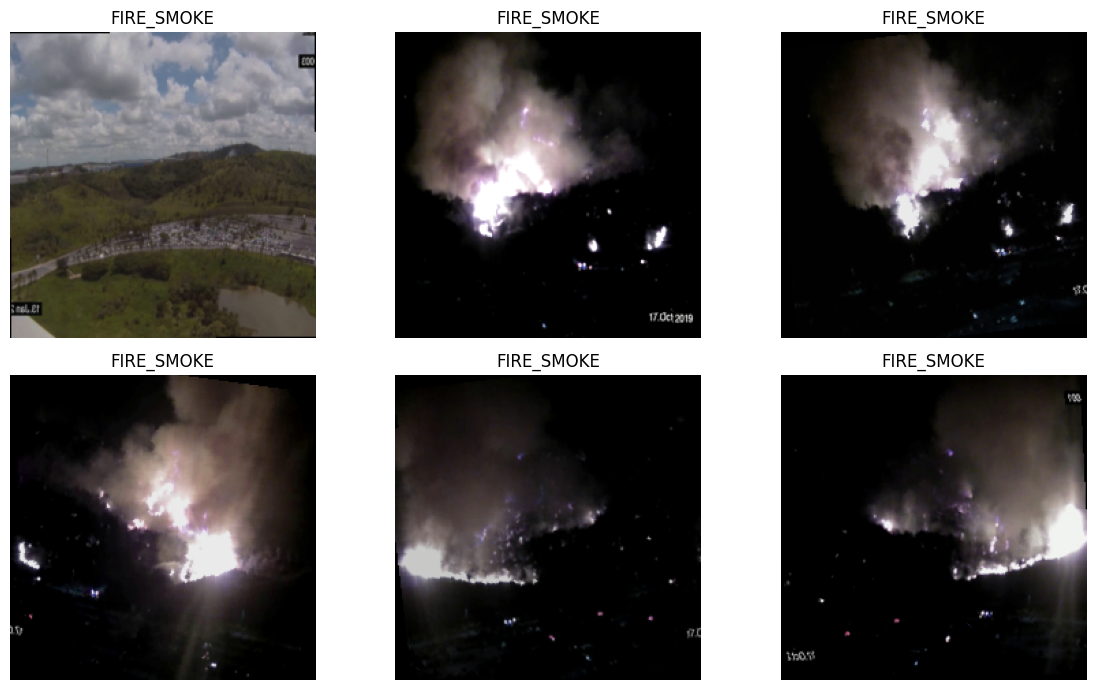

In [20]:
import matplotlib.pyplot as plt


sample_count = min(
    6,
    len(train_dataset),
)


figure = plt.figure(
    figsize=(12, 7)
)


mean_tensor = torch.tensor(
    IMAGENET_MEAN
).view(
    3,
    1,
    1,
)

std_tensor = torch.tensor(
    IMAGENET_STD
).view(
    3,
    1,
    1,
)


for plot_index in range(
    sample_count
):
    image_tensor, target, _ = (
        train_dataset[
            plot_index
        ]
    )

    image = (
        image_tensor
        * std_tensor
        + mean_tensor
    ).clamp(
        0,
        1,
    )

    axis = figure.add_subplot(
        2,
        3,
        plot_index + 1,
    )

    axis.imshow(
        image.permute(
            1,
            2,
            0,
        )
    )

    axis.set_title(
        INDEX_TO_CLASS[
            target
        ]
    )

    axis.axis(
        "off"
    )


plt.tight_layout()
plt.show()


## 20. MobileNetV3 Large com transfer learning

Usamos `MobileNetV3 Large` pré-treinada em ImageNet como baseline. Na primeira fase congelamos o extrator de características e treinamos apenas o classificador final.


In [21]:
from torchvision.models import (
    MobileNet_V3_Large_Weights,
    mobilenet_v3_large,
)


MODEL_NAME = (
    "mobilenet_v3_large"
)

MODEL_VERSION = "1.0.0"


weights = (
    MobileNet_V3_Large_Weights
    .DEFAULT
)


model = mobilenet_v3_large(
    weights=weights
)


for parameter in (
    model.features
    .parameters()
):
    parameter.requires_grad = (
        False
    )


in_features = (
    model.classifier[
        3
    ].in_features
)


model.classifier[
    3
] = nn.Linear(
    in_features,
    len(CLASS_NAMES),
)


model = model.to(
    DEVICE
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in (
        model.parameters()
    )
    if parameter.requires_grad
)


total_parameters = sum(
    parameter.numel()
    for parameter in (
        model.parameters()
    )
)


print(
    "Modelo:",
    MODEL_NAME,
)

print(
    "Parâmetros totais:",
    total_parameters,
)

print(
    "Parâmetros treináveis "
    "na fase 1:",
    trainable_parameters,
)


Modelo: mobilenet_v3_large
Parâmetros totais: 4205875
Parâmetros treináveis na fase 1: 1233923


## 21. Treinamento — fase 1: classificador


In [22]:
import copy
import time

from sklearn.metrics import (
    accuracy_score,
    f1_score,
)


LOSS_FUNCTION = (
    nn.CrossEntropyLoss()
)


USE_AMP = (
    DEVICE.type
    == "cuda"
)


def create_grad_scaler():
    if not USE_AMP:
        return None

    try:
        return torch.amp.GradScaler(
            "cuda"
        )

    except (
        AttributeError,
        TypeError,
    ):
        return (
            torch.cuda.amp
            .GradScaler()
        )


def run_epoch(
    model,
    loader,
    optimizer=None,
    scaler=None,
):
    training = (
        optimizer
        is not None
    )

    if training:
        model.train()
    else:
        model.eval()

    running_loss = 0.0

    y_true = []
    y_pred = []

    for images, targets, _ in tqdm(
        loader,
        leave=False,
    ):
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True,
        )

        if training:
            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(
            training
        ):
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=(
                    torch.float16
                    if DEVICE.type
                    == "cuda"
                    else torch.bfloat16
                ),
                enabled=USE_AMP,
            ):
                logits = model(
                    images
                )

                loss = (
                    LOSS_FUNCTION(
                        logits,
                        targets,
                    )
                )

            if training:
                if scaler is not None:
                    scaler.scale(
                        loss
                    ).backward()

                    scaler.step(
                        optimizer
                    )

                    scaler.update()

                else:
                    loss.backward()

                    optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = (
            logits
            .argmax(
                dim=1
            )
        )

        y_true.extend(
            targets
            .detach()
            .cpu()
            .tolist()
        )

        y_pred.extend(
            predictions
            .detach()
            .cpu()
            .tolist()
        )

    epoch_loss = (
        running_loss
        / len(
            loader.dataset
        )
    )

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=list(
            range(
                len(
                    CLASS_NAMES
                )
            )
        ),
        average="macro",
        zero_division=0,
    )

    return {
        "loss": float(
            epoch_loss
        ),
        "accuracy": float(
            accuracy
        ),
        "macro_f1": float(
            macro_f1
        ),
    }


def train_phase(
    *,
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs,
    phase_name,
    patience,
):
    scaler = (
        create_grad_scaler()
    )

    scheduler = (
        torch.optim
        .lr_scheduler
        .CosineAnnealingLR(
            optimizer,
            T_max=max(
                epochs,
                1,
            ),
        )
    )

    # O estado atual participa da comparação:
    # fine-tuning não pode substituir
    # automaticamente um modelo melhor.
    initial_val = run_epoch(
        model,
        val_loader,
    )

    best_metric = (
        initial_val[
            "macro_f1"
        ]
    )

    best_state = copy.deepcopy(
        model.state_dict()
    )

    stale_epochs = 0

    history = []

    print()
    print(
        f"{phase_name} — "
        "validação inicial:",
        initial_val,
    )

    for epoch in range(
        1,
        epochs + 1,
    ):
        started_at = (
            time.time()
        )

        train_metrics = run_epoch(
            model,
            train_loader,
            optimizer=optimizer,
            scaler=scaler,
        )

        val_metrics = run_epoch(
            model,
            val_loader,
        )

        learning_rate = (
            optimizer.param_groups[
                0
            ][
                "lr"
            ]
        )

        elapsed = (
            time.time()
            - started_at
        )

        row = {
            "phase": phase_name,
            "epoch": epoch,
            "learning_rate": (
                float(
                    learning_rate
                )
            ),
            "seconds": float(
                elapsed
            ),
            "train_loss": (
                train_metrics[
                    "loss"
                ]
            ),
            "train_accuracy": (
                train_metrics[
                    "accuracy"
                ]
            ),
            "train_macro_f1": (
                train_metrics[
                    "macro_f1"
                ]
            ),
            "val_loss": (
                val_metrics[
                    "loss"
                ]
            ),
            "val_accuracy": (
                val_metrics[
                    "accuracy"
                ]
            ),
            "val_macro_f1": (
                val_metrics[
                    "macro_f1"
                ]
            ),
        }

        history.append(
            row
        )

        print(
            f"[{phase_name}] "
            f"epoch {epoch}/{epochs} "
            f"| train loss "
            f"{row['train_loss']:.4f} "
            f"| train F1 "
            f"{row['train_macro_f1']:.4f} "
            f"| val loss "
            f"{row['val_loss']:.4f} "
            f"| val F1 "
            f"{row['val_macro_f1']:.4f} "
            f"| {elapsed:.1f}s"
        )

        if (
            val_metrics[
                "macro_f1"
            ]
            > best_metric
            + 1e-4
        ):
            best_metric = (
                val_metrics[
                    "macro_f1"
                ]
            )

            best_state = copy.deepcopy(
                model.state_dict()
            )

            stale_epochs = 0

        else:
            stale_epochs += 1

        scheduler.step()

        if (
            stale_epochs
            >= patience
        ):
            print(
                "Early stopping."
            )

            break

    model.load_state_dict(
        best_state
    )

    return (
        history,
        float(
            best_metric
        ),
    )


optimizer_phase_1 = (
    torch.optim.AdamW(
        (
            parameter
            for parameter in (
                model.parameters()
            )
            if parameter.requires_grad
        ),
        lr=1e-3,
        weight_decay=1e-4,
    )
)


history_phase_1, best_phase_1_f1 = (
    train_phase(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=(
            optimizer_phase_1
        ),
        epochs=3,
        phase_name="classifier",
        patience=2,
    )
)


print()
print(
    "Melhor macro-F1 "
    "fase 1:",
    best_phase_1_f1,
)


  0%|          | 0/68 [00:00<?, ?it/s]


classifier — validação inicial: {'loss': 1.0567903420097182, 'accuracy': 0.4905923344947735, 'macro_f1': 0.4831257396789191}


  0%|          | 0/314 [00:00<?, ?it/s]

  0%|          | 0/68 [00:00<?, ?it/s]

[classifier] epoch 1/3 | train loss 0.3435 | train F1 0.8674 | val loss 0.3107 | val F1 0.8730 | 437.2s


...

  0%|          | 0/68 [00:00<?, ?it/s]

[classifier] epoch 2/3 | train loss 0.2054 | train F1 0.9251 | val loss 0.2899 | val F1 0.8842 | 418.8s


  0%|          | 0/314 [00:00<?, ?it/s]

  0%|          | 0/68 [00:00<?, ?it/s]

[classifier] epoch 3/3 | train loss 0.1535 | train F1 0.9445 | val loss 0.2509 | val F1 0.9081 | 413.8s

Melhor macro-F1 fase 1: 0.9081223509155595


## 22. Fine-tuning

Descongelamos apenas os quatro últimos blocos do extrator visual e reduzimos a taxa de aprendizado. Isso adapta representações de alto nível ao domínio sem retreinar toda a rede de uma vez.


In [23]:
for parameter in (
    model.features[
        -4:
    ].parameters()
):
    parameter.requires_grad = (
        True
    )


trainable_parameters_phase_2 = sum(
    parameter.numel()
    for parameter in (
        model.parameters()
    )
    if parameter.requires_grad
)


print(
    "Parâmetros treináveis "
    "na fase 2:",
    trainable_parameters_phase_2,
)


optimizer_phase_2 = (
    torch.optim.AdamW(
        (
            parameter
            for parameter in (
                model.parameters()
            )
            if parameter.requires_grad
        ),
        lr=1e-4,
        weight_decay=1e-4,
    )
)


history_phase_2, best_phase_2_f1 = (
    train_phase(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=(
            optimizer_phase_2
        ),
        epochs=8,
        phase_name="fine_tuning",
        patience=3,
    )
)


training_history = pd.DataFrame(
    history_phase_1
    + history_phase_2
)


history_path = (
    OUTPUT_DIR
    / "training_history.csv"
)

training_history.to_csv(
    history_path,
    index=False,
)


print()
print(
    "Melhor macro-F1 "
    "fase 1:",
    best_phase_1_f1,
)

print(
    "Melhor macro-F1 "
    "fase 2:",
    best_phase_2_f1,
)

display(
    training_history
)


Parâmetros treináveis na fase 2: 3413387


  0%|          | 0/68 [00:00<?, ?it/s]


fine_tuning — validação inicial: {'loss': 0.2509430488227552, 'accuracy': 0.9045296167247386, 'macro_f1': 0.9081223509155595}


  0%|          | 0/314 [00:00<?, ?it/s]

  0%|          | 0/68 [00:00<?, ?it/s]

...

[fine_tuning] epoch 6/8 | train loss 0.0143 | train F1 0.9963 | val loss 0.1974 | val F1 0.9319 | 398.7s


  0%|          | 0/314 [00:00<?, ?it/s]

  0%|          | 0/68 [00:00<?, ?it/s]

[fine_tuning] epoch 7/8 | train loss 0.0136 | train F1 0.9964 | val loss 0.2059 | val F1 0.9338 | 399.2s
Early stopping.

Melhor macro-F1 fase 1: 0.9081223509155595
Melhor macro-F1 fase 2: 0.9383295138414928


,phase,epoch,learning_rate,seconds,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,classifier,1,0.001000,437.161796,0.343504,0.861511,0.867389,0.310745,0.865738,0.872979
1,classifier,2,0.000750,418.786560,0.205410,0.921518,0.925059,0.289885,0.880604,0.884181
2,classifier,3,0.000250,413.752048,0.153521,0.941935,0.944547,0.250943,0.904530,0.908122
3,fine_tuning,1,0.000100,410.469076,0.108458,0.960161,0.961990,0.215884,0.914750,0.917504
4,fine_tuning,2,0.000096,410.189339,0.059274,0.978736,0.979690,0.241812,0.907549,0.911823
5,fine_tuning,3,0.000085,407.227479,0.040195,0.986405,0.987107,0.186195,0.930081,0.931880
6,fine_tuning,4,0.000069,409.176256,0.026188,0.991136,0.991601,0.195152,0.937515,0.938330
7,fine_tuning,5,0.000050,406.653282,0.021603,0.992680,0.993063,0.218041,0.922880,0.922323
8,fine_tuning,6,0.000031,398.698363,0.014253,0.996166,0.996319,0.197441,0.932172,0.931927
9,fine_tuning,7,0.000015,399.161012,0.013618,0.996116,0.996380,0.205868,0.935424,0.933774


## 23. Avaliação final no conjunto de teste


In [24]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)


@torch.no_grad()
def predict_probabilities(
    model,
    loader,
):
    model.eval()

    probability_batches = []
    target_batches = []
    index_batches = []

    for images, targets, indices in tqdm(
        loader,
        leave=False,
    ):
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=(
                torch.float16
                if DEVICE.type
                == "cuda"
                else torch.bfloat16
            ),
            enabled=USE_AMP,
        ):
            logits = model(
                images
            )

        probabilities = (
            torch.softmax(
                logits.float(),
                dim=1,
            )
        )

        probability_batches.append(
            probabilities.cpu()
        )

        target_batches.append(
            targets.cpu()
        )

        index_batches.append(
            indices.cpu()
        )

    return (
        torch.cat(
            probability_batches
        ).numpy(),
        torch.cat(
            target_batches
        ).numpy(),
        torch.cat(
            index_batches
        ).numpy(),
    )


test_probabilities, test_targets, test_indices = (
    predict_probabilities(
        model,
        test_loader,
    )
)


test_predictions = (
    test_probabilities
    .argmax(
        axis=1
    )
)


test_accuracy = accuracy_score(
    test_targets,
    test_predictions,
)


test_macro_f1 = f1_score(
    test_targets,
    test_predictions,
    labels=list(
        range(
            len(
                CLASS_NAMES
            )
        )
    ),
    average="macro",
    zero_division=0,
)


print(
    "Test accuracy:",
    round(
        test_accuracy,
        4,
    ),
)

print(
    "Test macro-F1:",
    round(
        test_macro_f1,
        4,
    ),
)


test_report = classification_report(
    test_targets,
    test_predictions,
    labels=list(
        range(
            len(
                CLASS_NAMES
            )
        )
    ),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)


display(
    pd.DataFrame(
        test_report
    ).transpose()
)


  0%|          | 0/68 [00:00<?, ?it/s]

Test accuracy: 0.9456
Test macro-F1: 0.9489


,precision,recall,f1-score,support
FLOOD_WATER,0.976168,0.973384,0.974774,1052.000000
FIRE_SMOKE,0.952909,0.915502,0.933831,1503.000000
OTHER,0.922185,0.954857,0.938237,1750.000000
accuracy,0.945645,0.945645,0.945645,0.945645
macro avg,0.950421,0.947915,0.948947,4305.000000
weighted avg,0.946103,0.945645,0.945627,4305.000000


## 24. Matriz de confusão


In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
)


confusion = confusion_matrix(
    test_targets,
    test_predictions,
    labels=list(
        range(
            len(
                CLASS_NAMES
            )
        )
    ),
)


figure, axis = plt.subplots(
    figsize=(8, 7)
)


ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
).plot(
    ax=axis,
    values_format="d",
)


plt.tight_layout()


confusion_matrix_path = (
    OUTPUT_DIR
    / "confusion_matrix.png"
)


figure.savefig(
    confusion_matrix_path,
    dpi=160,
    bbox_inches="tight",
)


plt.show()


print(
    "Matriz salva em:",
    confusion_matrix_path,
)


## 25. Precision, recall e F1 por classe


In [26]:
per_class_metrics = (
    pd.DataFrame(
        {
            label: (
                test_report[
                    label
                ]
            )
            for label in (
                CLASS_NAMES
            )
        }
    )
    .transpose()
    .reset_index(
        names="label"
    )
)


display(
    per_class_metrics
)


per_class_metrics_path = (
    OUTPUT_DIR
    / "per_class_metrics.csv"
)


per_class_metrics.to_csv(
    per_class_metrics_path,
    index=False,
)


,label,precision,recall,f1-score,support
0,FLOOD_WATER,0.976168,0.973384,0.974774,1052.0
1,FIRE_SMOKE,0.952909,0.915502,0.933831,1503.0
2,OTHER,0.922185,0.954857,0.938237,1750.0


## 26. Análise de erros


In [27]:
test_max_confidence = (
    test_probabilities
    .max(
        axis=1
    )
)


error_mask = (
    test_predictions
    != test_targets
)


error_positions = np.where(
    error_mask
)[0]


error_rows = []


for position in error_positions:
    dataset_index = int(
        test_indices[
            position
        ]
    )

    source_row = (
        test_frame
        .iloc[
            dataset_index
        ]
    )

    predicted_index = int(
        test_predictions[
            position
        ]
    )

    true_index = int(
        test_targets[
            position
        ]
    )

    error_rows.append(
        {
            "source_dataset": (
                source_row[
                    "source_dataset"
                ]
            ),
            "relative_path": (
                source_row[
                    "relative_path"
                ]
            ),
            "true_label": (
                INDEX_TO_CLASS[
                    true_index
                ]
            ),
            "predicted_label": (
                INDEX_TO_CLASS[
                    predicted_index
                ]
            ),
            "confidence": float(
                test_max_confidence[
                    position
                ]
            ),
            "group_id": (
                source_row[
                    "group_id"
                ]
            ),
        }
    )


error_analysis = pd.DataFrame(
    error_rows
)


if not error_analysis.empty:
    error_analysis = (
        error_analysis
        .sort_values(
            "confidence",
            ascending=False,
        )
        .reset_index(drop=True)
    )


error_analysis_path = (
    OUTPUT_DIR
    / "error_analysis.csv"
)


error_analysis.to_csv(
    error_analysis_path,
    index=False,
)


print(
    "Erros no teste:",
    len(error_analysis),
)


display(
    error_analysis.head(30)
)


Erros no teste: 234


,source_dataset,relative_path,true_label,predicted_label,confidence,group_id
0,dfire,data/train/images/WEB02389.jpg,OTHER,FLOOD_WATER,0.999997,phash-group-010548
1,flood-kaggle-fallback,Dataset/Flood Images/flood_953.jpg,FLOOD_WATER,OTHER,0.999992,phash-group-017052
2,dfire,data/train/images/WEB05884.jpg,FIRE_SMOKE,OTHER,0.999841,phash-group-003835
3,dfire,data/test/images/WEB10263.jpg,OTHER,FIRE_SMOKE,0.999817,phash-group-008456
4,dfire,data/train/images/WEB03270.jpg,OTHER,FLOOD_WATER,0.999508,phash-group-011266
5,dfire,data/train/images/WEB07818.jpg,FIRE_SMOKE,OTHER,0.999410,phash-group-005261
6,dfire,data/train/images/AoF05103.jpg,FIRE_SMOKE,OTHER,0.999371,phash-group-001647
7,dfire,data/train/images/WEB09339.jpg,FIRE_SMOKE,OTHER,0.997955,phash-group-006439
8,dfire,data/train/images/WEB07259.jpg,FIRE_SMOKE,OTHER,0.997238,phash-group-004817
9,dfire,data/train/images/WEB02263.jpg,OTHER,FLOOD_WATER,0.997128,phash-group-010445


## 27. Calibração da decisão `UNCERTAIN`

A confiança máxima do softmax é usada como sinal de rejeição.

O limiar é escolhido **somente na validação**. Procuramos o menor limiar que mantenha pelo menos 90% de acurácia entre as previsões aceitas e pelo menos 50% de cobertura. Se nenhum ponto satisfizer esses requisitos, usamos o melhor compromisso encontrado na validação.

Depois aplicamos o limiar congelado ao teste.


In [28]:
TARGET_ACCEPTED_ACCURACY = 0.90
MIN_ACCEPTED_COVERAGE = 0.50


val_probabilities, val_targets, _ = (
    predict_probabilities(
        model,
        val_loader,
    )
)


val_predictions = (
    val_probabilities
    .argmax(
        axis=1
    )
)


val_confidences = (
    val_probabilities
    .max(
        axis=1
    )
)


threshold_rows = []


for threshold in np.arange(
    0.50,
    0.951,
    0.01,
):
    accepted = (
        val_confidences
        >= threshold
    )

    accepted_count = int(
        accepted.sum()
    )

    coverage = float(
        accepted.mean()
    )

    if accepted_count > 0:
        accepted_accuracy = float(
            accuracy_score(
                val_targets[
                    accepted
                ],
                val_predictions[
                    accepted
                ],
            )
        )

        accepted_macro_f1 = float(
            f1_score(
                val_targets[
                    accepted
                ],
                val_predictions[
                    accepted
                ],
                labels=list(
                    range(
                        len(
                            CLASS_NAMES
                        )
                    )
                ),
                average="macro",
                zero_division=0,
            )
        )

    else:
        accepted_accuracy = 0.0
        accepted_macro_f1 = 0.0

    threshold_rows.append(
        {
            "threshold": float(
                round(
                    threshold,
                    2,
                )
            ),
            "accepted_count": (
                accepted_count
            ),
            "coverage": coverage,
            "accepted_accuracy": (
                accepted_accuracy
            ),
            "accepted_macro_f1": (
                accepted_macro_f1
            ),
        }
    )


threshold_table = pd.DataFrame(
    threshold_rows
)


valid_thresholds = threshold_table[
    (
        threshold_table[
            "accepted_accuracy"
        ]
        >= TARGET_ACCEPTED_ACCURACY
    )
    & (
        threshold_table[
            "coverage"
        ]
        >= MIN_ACCEPTED_COVERAGE
    )
]


if not valid_thresholds.empty:
    selected_row = (
        valid_thresholds
        .sort_values(
            [
                "coverage",
                "threshold",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .iloc[0]
    )

    threshold_selection_reason = (
        "target_accuracy_and_coverage"
    )

else:
    fallback_table = (
        threshold_table.copy()
    )

    fallback_table[
        "utility"
    ] = (
        fallback_table[
            "accepted_accuracy"
        ]
        * fallback_table[
            "coverage"
        ]
    )

    selected_row = (
        fallback_table
        .sort_values(
            [
                "utility",
                "accepted_accuracy",
                "coverage",
            ],
            ascending=False,
        )
        .iloc[0]
    )

    threshold_selection_reason = (
        "best_validation_utility"
    )


UNCERTAIN_THRESHOLD = float(
    selected_row[
        "threshold"
    ]
)


print(
    "Threshold escolhido:",
    UNCERTAIN_THRESHOLD,
)

print(
    "Motivo:",
    threshold_selection_reason,
)

print()
print(
    "Validação no threshold:"
)

display(
    pd.DataFrame(
        [
            selected_row
        ]
    )
)


threshold_curve_path = (
    OUTPUT_DIR
    / "uncertain_threshold_curve.csv"
)


threshold_table.to_csv(
    threshold_curve_path,
    index=False,
)


test_confidences = (
    test_probabilities
    .max(
        axis=1
    )
)


test_accepted = (
    test_confidences
    >= UNCERTAIN_THRESHOLD
)


test_coverage = float(
    test_accepted.mean()
)


test_uncertain_count = int(
    (
        ~test_accepted
    ).sum()
)


if test_accepted.any():
    test_accepted_accuracy = float(
        accuracy_score(
            test_targets[
                test_accepted
            ],
            test_predictions[
                test_accepted
            ],
        )
    )

    test_accepted_macro_f1 = float(
        f1_score(
            test_targets[
                test_accepted
            ],
            test_predictions[
                test_accepted
            ],
            labels=list(
                range(
                    len(
                        CLASS_NAMES
                    )
                )
            ),
            average="macro",
            zero_division=0,
        )
    )

else:
    test_accepted_accuracy = 0.0
    test_accepted_macro_f1 = 0.0


print()
print(
    "Teste — cobertura:",
    round(
        test_coverage,
        4,
    ),
)

print(
    "Teste — UNCERTAIN:",
    test_uncertain_count,
)

print(
    "Teste — accuracy entre aceitas:",
    round(
        test_accepted_accuracy,
        4,
    ),
)

print(
    "Teste — macro-F1 entre aceitas:",
    round(
        test_accepted_macro_f1,
        4,
    ),
)


  0%|          | 0/68 [00:00<?, ?it/s]

Threshold escolhido: 0.5
Motivo: target_accuracy_and_coverage

Validação no threshold:


,threshold,accepted_count,coverage,accepted_accuracy,accepted_macro_f1
0,0.5,4275.0,0.993031,0.940351,0.941403



Teste — cobertura: 0.9986
Teste — UNCERTAIN: 6
Teste — accuracy entre aceitas: 0.9465
Teste — macro-F1 entre aceitas: 0.9498


## 28. Exportação ONNX e checkpoint PyTorch


In [ ]:
import onnx


ARTIFACT_BASENAME = (
    "kamara_visual_"
    "mobilenet_v3_large_v1"
)


final_pth_path = (
    OUTPUT_DIR
    / f"{ARTIFACT_BASENAME}.pth"
)


final_onnx_path = (
    OUTPUT_DIR
    / f"{ARTIFACT_BASENAME}.onnx"
)


model = model.to(
    "cpu"
)

model.eval()


torch.save(
    {
        "model_name": MODEL_NAME,
        "model_version": (
            MODEL_VERSION
        ),
        "model_state_dict": (
            model.state_dict()
        ),
        "class_names": (
            CLASS_NAMES
        ),
        "class_to_index": (
            CLASS_TO_INDEX
        ),
        "input_size": (
            IMAGE_SIZE
        ),
        "normalization_mean": (
            IMAGENET_MEAN
        ),
        "normalization_std": (
            IMAGENET_STD
        ),
        "uncertain_threshold": (
            UNCERTAIN_THRESHOLD
        ),
    },
    final_pth_path,
)


dummy_input = torch.randn(
    1,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
)


export_kwargs = {
    "export_params": True,
    "opset_version": 17,
    "do_constant_folding": True,
    "input_names": [
        "image"
    ],
    "output_names": [
        "logits"
    ],
    "dynamic_axes": {
        "image": {
            0: "batch"
        },
        "logits": {
            0: "batch"
        },
    },
}


try:
    torch.onnx.export(
        model,
        dummy_input,
        final_onnx_path,
        dynamo=False,
        **export_kwargs,
    )

except TypeError:
    torch.onnx.export(
        model,
        dummy_input,
        final_onnx_path,
        **export_kwargs,
    )


onnx_model = onnx.load(
    final_onnx_path
)

onnx.checker.check_model(
    onnx_model
)


print(
    "PyTorch checkpoint:",
    final_pth_path,
)

print(
    "ONNX:",
    final_onnx_path,
)

print(
    "Tamanho ONNX:",
    round(
        final_onnx_path
        .stat()
        .st_size
        / 1024**2,
        2,
    ),
    "MB",
)


## 29. Validação do ONNX contra PyTorch


In [ ]:
import onnxruntime as ort


onnx_session = (
    ort.InferenceSession(
        str(
            final_onnx_path
        ),
        providers=[
            "CPUExecutionProvider"
        ],
    )
)


sample_images, _, _ = next(
    iter(
        test_loader
    )
)


sample_images = (
    sample_images[
        :8
    ]
    .cpu()
)


with torch.no_grad():
    pytorch_logits = (
        model(
            sample_images
        )
        .numpy()
    )


onnx_logits = (
    onnx_session.run(
        [
            "logits"
        ],
        {
            "image": (
                sample_images
                .numpy()
                .astype(
                    np.float32
                )
            )
        },
    )[0]
)


max_absolute_difference = float(
    np.max(
        np.abs(
            pytorch_logits
            - onnx_logits
        )
    )
)


pytorch_predictions = (
    pytorch_logits
    .argmax(
        axis=1
    )
)


onnx_predictions = (
    onnx_logits
    .argmax(
        axis=1
    )
)


predictions_equal = bool(
    np.array_equal(
        pytorch_predictions,
        onnx_predictions,
    )
)


print(
    "Máxima diferença absoluta:",
    max_absolute_difference,
)

print(
    "Predições PyTorch == ONNX:",
    predictions_equal,
)


if not predictions_equal:
    raise RuntimeError(
        "A validação ONNX produziu "
        "classes diferentes do PyTorch."
    )


## 30. Artefatos finais e pacote para download


In [ ]:
import platform
import shutil
from datetime import (
    datetime,
    timezone,
)


def file_sha256(
    path: Path,
) -> str:
    return sha256_file(
        path
    )


final_split_manifest_path = (
    OUTPUT_DIR
    / "split_manifest.csv"
)


split_manifest.to_csv(
    final_split_manifest_path,
    index=False,
)


class_mapping = {
    "modelType": "VISUAL",
    "modelName": MODEL_NAME,
    "modelVersion": MODEL_VERSION,
    "indexToLabel": {
        str(index): label
        for index, label in (
            INDEX_TO_CLASS.items()
        )
    },
    "labelToIndex": (
        CLASS_TO_INDEX
    ),
    "uncertain": {
        "label": "UNCERTAIN",
        "threshold": (
            UNCERTAIN_THRESHOLD
        ),
        "selectionReason": (
            threshold_selection_reason
        ),
    },
    "input": {
        "size": [
            IMAGE_SIZE,
            IMAGE_SIZE,
        ],
        "colorMode": "RGB",
        "normalizationMean": (
            IMAGENET_MEAN
        ),
        "normalizationStd": (
            IMAGENET_STD
        ),
    },
}


class_mapping_path = (
    OUTPUT_DIR
    / "class_mapping.json"
)


class_mapping_path.write_text(
    json.dumps(
        class_mapping,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


metrics = {
    "test": {
        "accuracy": float(
            test_accuracy
        ),
        "macroF1": float(
            test_macro_f1
        ),
        "classificationReport": (
            test_report
        ),
    },
    "uncertainPolicy": {
        "threshold": (
            UNCERTAIN_THRESHOLD
        ),
        "selectionReason": (
            threshold_selection_reason
        ),
        "targetAcceptedAccuracy": (
            TARGET_ACCEPTED_ACCURACY
        ),
        "minimumAcceptedCoverage": (
            MIN_ACCEPTED_COVERAGE
        ),
        "testCoverage": (
            test_coverage
        ),
        "testUncertainCount": (
            test_uncertain_count
        ),
        "testAcceptedAccuracy": (
            test_accepted_accuracy
        ),
        "testAcceptedMacroF1": (
            test_accepted_macro_f1
        ),
    },
}


metrics_path = (
    OUTPUT_DIR
    / "metrics.json"
)


metrics_path.write_text(
    json.dumps(
        metrics,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


gpu_name = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else None
)


run_metadata = {
    "createdAt": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),
    "seed": SEED,
    "python": (
        platform.python_version()
    ),
    "torch": (
        torch.__version__
    ),
    "torchvision": (
        torchvision.__version__
    ),
    "gpu": gpu_name,
    "model": {
        "name": MODEL_NAME,
        "version": MODEL_VERSION,
        "pretrainedWeights": (
            str(weights)
        ),
        "inputSize": (
            IMAGE_SIZE
        ),
    },
    "training": {
        "phase1EpochLimit": 3,
        "phase1LearningRate": (
            1e-3
        ),
        "phase2EpochLimit": 8,
        "phase2LearningRate": (
            1e-4
        ),
        "batchSize": (
            BATCH_SIZE
        ),
        "weightDecay": (
            1e-4
        ),
        "amp": (
            USE_AMP
        ),
    },
    "data": {
        "dfireHandle": (
            DFIRE_KAGGLE_HANDLE
        ),
        "floodHandle": (
            FLOOD_KAGGLE_HANDLE
        ),
        "floodSourceDataset": (
            FLOOD_SOURCE_DATASET
        ),
        "pHashMaximumDistance": (
            PHASH_MAX_DISTANCE
        ),
        "exactDuplicatesRemoved": (
            exact_duplicates_removed
        ),
        "nearDuplicateConflictGroupsRemoved": (
            len(
                near_duplicate_conflict_groups
            )
        ),
        "splitRatios": (
            SPLIT_RATIOS
        ),
        "splitCounts": {
            split_name: int(
                count
            )
            for split_name, count in (
                split_manifest[
                    "split"
                ]
                .value_counts()
                .items()
            )
        },
        "classCounts": {
            label: int(
                count
            )
            for label, count in (
                split_manifest[
                    "label"
                ]
                .value_counts()
                .items()
            )
        },
    },
    "onnx": {
        "filename": (
            final_onnx_path.name
        ),
        "sha256": (
            file_sha256(
                final_onnx_path
            )
        ),
        "maxAbsoluteDifference": (
            max_absolute_difference
        ),
        "predictionParity": (
            predictions_equal
        ),
    },
}


run_metadata_path = (
    OUTPUT_DIR
    / "run_metadata.json"
)


run_metadata_path.write_text(
    json.dumps(
        run_metadata,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


archive_base = (
    WORK_DIR
    / ARTIFACT_BASENAME
)


archive_path = Path(
    shutil.make_archive(
        str(
            archive_base
        ),
        "zip",
        root_dir=OUTPUT_DIR,
    )
)


print(
    "Artefatos gerados:"
)

for path in sorted(
    OUTPUT_DIR.iterdir()
):
    if path.is_file():
        print(
            "-",
            path.name,
            f"({path.stat().st_size / 1024**2:.2f} MB)",
        )


print()
print(
    "Pacote final:",
    archive_path,
)

print(
    "Tamanho:",
    round(
        archive_path
        .stat()
        .st_size
        / 1024**2,
        2,
    ),
    "MB",
)


### Download do pacote final

Execute a célula abaixo somente depois que todas as etapas anteriores terminarem sem erro. O ZIP contém o ONNX, checkpoint PyTorch, manifesto de split, métricas, histórico, matriz de confusão e metadados de reprodução.


In [32]:
from google.colab import files

files.download(
    str(
        archive_path
    )
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>